# Our model vs online estimates: homes.co.nz and OneRoof (RQ2)

**Data:** `online_valuation.csv` -- the 50 most recent sales in the dataset
(28 July -- 18 August 2026). For each, two free online estimates were
recorded: the homes.co.nz **HomesEstimate** (column `online_estimate`) and
the **OneRoof** estimate (column `oneroot`). homes.co.nz was recorded on
**9 July 2026** and OneRoof in **early July 2026** (the exact day was not
noted). Both are at least 19 days *before* every sale, so neither could
have used the sale price.

**Our model:** XGBoost with all 27 features, same settings as
`train.ipynb`. Two versions are compared:

1. **Ours (fold 5)** -- the prediction already in the CSV, from the model
   trained on sales up to 24 January 2026 (the out-of-fold prediction used
   everywhere else in the project).
2. **Ours (to 9 July)** -- the same model retrained on all sales up to
   9 July 2026, the date the online estimates were captured. This is the
   like-for-like comparison: both predictors then know the market up to
   the same day.

Homes missing either online estimate, or outside the model's price limits,
are left out, so every number below compares all predictors on the **same
homes**.

## 1. Load the comparison table

In [1]:
import numpy as np
import pandas as pd

CAPTURE_DATE = pd.Timestamp("2026-07-09")   # homes.co.nz estimates recorded
ONEROOF_DATE = pd.Timestamp("2026-07-09")   # OneRoof recorded in early July; 9 July is the latest it could be
ONEROOF_COL = "oneroot"                     # column name in online_valuation.csv

ov = pd.read_csv("online_valuation.csv", parse_dates=["sale_date"])
print(f"{len(ov)} homes in the file")
needed = ["online_estimate", ONEROOF_COL, "our_prediction"]
missing = ov[ov[needed].isna().any(axis=1)]
print(f"Left out ({len(missing)}): a missing online estimate or outside the model's price limits")
display(missing[["no", "address", "sale_price"] + needed])

cmp = ov.dropna(subset=needed).copy()
assert (cmp["sale_date"] > max(CAPTURE_DATE, ONEROOF_DATE)).all(), "every estimate must be captured before the sale"
days = (cmp["sale_date"] - CAPTURE_DATE).dt.days
print(f"Compared: {len(cmp)} homes, sold {days.min()}-{days.max()} days after the estimates were captured")

50 homes in the file
Left out (5): a missing online estimate or outside the model's price limits


,no,address,sale_price,online_estimate,oneroot,our_prediction
12,13,"22/85 Edmonton Road, Henderson",370000,NaN,NaN,NaN
17,18,"7/7 Reeves Avenue, Papatoetoe",783000,NaN,NaN,902000.0
22,23,"36 Powrie Street, Glenfield",1346000,1140000.0,NaN,1218000.0
41,42,"23 Muritai Road, Milford",7200000,NaN,NaN,NaN
43,44,"17 Marino Street, Drury",756000,NaN,765000.0,828000.0


Compared: 45 homes, sold 19-40 days after the estimates were captured


## 2. Retrain our model up to 9 July 2026

Same data, features and per-fold processing as `train.ipynb`
(sections 1 and 3 copied unchanged). Training rows are all sales **before
9 July 2026**; the 1st/99th-percentile price trim and the medians are
learned from them only.

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import OrdinalEncoder

pd.set_option("display.max_columns", 70)

df = pd.read_parquet("./cache/remake_dataset.parquet")

# TimeSeriesSplit assumes row order IS time order -- sort explicitly rather
# than relying on the order the parquet was written in.
df = df.sort_values("sale_date_parsed").reset_index(drop=True)
print(f"Loaded {df.shape[0]:,} rows, {df.shape[1]} columns")
print(f"Date range: {df['sale_date_parsed'].min().date()} to {df['sale_date_parsed'].max().date()}")

Loaded 59,708 rows, 33 columns
Date range: 2024-01-01 to 2026-08-18


In [3]:
ID_COLS = ["valuation_id_concat", "sale_id", "sale_date_parsed"]
TARGET = "sale_price_gross"

CAT_COLS = [
    "property_type", "building_age_indicator", "building_condition_indicator",
    "building_construction_indicator", "noise_category_combination",
]
BOOL_COLS = ["in_flood_plain"]
NUM_COLS = [
    # property
    "land_area", "building_total_floor_area",
    "off_street_parking", "mass_garage_under_main_roof", "mass_garage_freestanding",
    # location / spatial
    "latitude", "longitude", "distance_to_cbd", "walk_supermarket_network_m",
    "walk_bus_stop_network_m", "distance_to_school", "area_level_deprivation_index",
    # socioeconomic
    "median_personal_income_by_sa", "employment_rate_by_sa", "unemployment_rate_by_sa",
    "population_counts_by_sa", "population_density",
    # environment
    "distance_to_coastline",
    # market / time
    "building_consents", "sale_year", "sale_month",
]
FEATURE_COLS = CAT_COLS + BOOL_COLS + NUM_COLS

# Near-duplicates dropped after feature_reduction.ipynb (set C):
# sale_quarter is calculated from sale_month, and mass_total_floor_area repeats
# building_total_floor_area (rho 0.96). Dropping both cost under 0.5% RMSE.
DROPPED_COLS = ["sale_quarter", "mass_total_floor_area"]

unassigned = set(df.columns) - set(FEATURE_COLS) - set(ID_COLS) - {TARGET} - set(DROPPED_COLS)
missing = set(FEATURE_COLS) - set(df.columns)
assert not unassigned, f"Columns not assigned to any group: {unassigned}"
assert not missing, f"Feature columns not in dataset: {missing}"

print(f"{len(FEATURE_COLS)} features: {len(CAT_COLS)} categorical, {len(BOOL_COLS)} boolean, {len(NUM_COLS)} numeric")

27 features: 5 categorical, 1 boolean, 21 numeric


In [4]:
def prepare_fold(train_df, test_df):
    """Encode, impute and price-trim one fold. Returns X/y for train and test."""
    encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    encoder.fit(train_df[CAT_COLS])

    X_train = train_df[FEATURE_COLS].copy()
    X_test = test_df[FEATURE_COLS].copy()
    X_train[CAT_COLS] = encoder.transform(train_df[CAT_COLS])
    X_test[CAT_COLS] = encoder.transform(test_df[CAT_COLS])
    for col in BOOL_COLS:
        X_train[col] = X_train[col].astype(int)
        X_test[col] = X_test[col].astype(int)
    X_train = X_train.astype(float)
    X_test = X_test.astype(float)

    nan_cols = [c for c in NUM_COLS if X_train[c].isna().any() or X_test[c].isna().any()]
    train_medians = X_train[nan_cols].median()
    X_train[nan_cols] = X_train[nan_cols].fillna(train_medians)
    X_test[nan_cols] = X_test[nan_cols].fillna(train_medians)

    y_train = train_df[TARGET].values
    y_test = test_df[TARGET].values
    p1, p99 = np.quantile(y_train, [0.01, 0.99])
    train_keep = (y_train >= p1) & (y_train <= p99)
    test_keep = (y_test >= p1) & (y_test <= p99)

    return {
        "X_train": X_train[train_keep], "y_train": y_train[train_keep],
        "X_test": X_test[test_keep], "y_test": y_test[test_keep],
        "test_idx": test_df.index[test_keep], "price_limits": (p1, p99),
    }

In [5]:
from xgboost import XGBRegressor

# Find the 50 homes in the dataset (the checklist kept their valuation ids).
ids = pd.read_csv("cache/_scratch/online_valuation_recent50.csv",
                  usecols=["no", "valuation_id_concat", "sale_date", "sale_price"], parse_dates=["sale_date"])
key = df.reset_index().merge(
    ids, left_on=["valuation_id_concat", "sale_date_parsed", "sale_price_gross"],
    right_on=["valuation_id_concat", "sale_date", "sale_price"],
).set_index("no")["index"]
assert key.index.is_unique and set(cmp["no"]) <= set(key.index)

train_df = df[df["sale_date_parsed"] < CAPTURE_DATE]
test_df = df.loc[key.loc[cmp["no"]].values]
f = prepare_fold(train_df, test_df)
assert len(f["y_test"]) == len(cmp), "a compared home fell outside the retrained model's price limits"

model_jul = XGBRegressor(
    n_estimators=500, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1,
).fit(f["X_train"], f["y_train"])
pred_jul = pd.Series(model_jul.predict(f["X_test"]), index=f["test_idx"])
cmp["ours_to_9jul"] = pred_jul.loc[key.loc[cmp["no"]].values].round(-3).values
print(f"Retrained on {len(f['y_train']):,} sales up to {train_df['sale_date_parsed'].max().date()}")

Retrained on 58,223 sales up to 2026-07-08


## 3. Accuracy on the same homes

Same metrics as the rest of the project, plus the share of homes predicted
within 5% and 10% of the sale price (a common way to report automated
valuations), and the median signed error (positive = predicts too high).

In [6]:
PREDICTORS = {
    "homes.co.nz (9 Jul)": "online_estimate",
    "OneRoof (early Jul)": ONEROOF_COL,
    "Ours (fold 5, to 24 Jan)": "our_prediction",
    "Ours (retrained to 9 Jul)": "ours_to_9jul",
}
ONLINE = ["homes.co.nz (9 Jul)", "OneRoof (early Jul)"]
OURS = ["Ours (fold 5, to 24 Jan)", "Ours (retrained to 9 Jul)"]
y = cmp["sale_price"].values
pct = {name: (cmp[col].values - y) / y * 100 for name, col in PREDICTORS.items()}

summary = pd.DataFrame({
    name: {
        "MAPE %": np.mean(np.abs(e)),
        "median abs error %": np.median(np.abs(e)),
        "MAE $": np.mean(np.abs(cmp[col].values - y)),
        "RMSE $": np.sqrt(np.mean((cmp[col].values - y) ** 2)),
        "within 5% (share)": np.mean(np.abs(e) <= 5) * 100,
        "within 10% (share)": np.mean(np.abs(e) <= 10) * 100,
        "median signed error %": np.median(e),
    }
    for (name, col), e in zip(PREDICTORS.items(), pct.values())
}).T
print(f"n = {len(cmp)} homes")
summary.round(1)

n = 45 homes


,MAPE %,median abs error %,MAE $,RMSE $,within 5% (share),within 10% (share),median signed error %
homes.co.nz (9 Jul),5.8,4.8,70253.1,91029.2,51.1,77.8,-0.9
OneRoof (early Jul),5.8,3.8,72917.3,100664.8,57.8,80.0,0.0
"Ours (fold 5, to 24 Jan)",9.6,8.6,125719.8,200314.0,31.1,55.6,0.8
Ours (retrained to 9 Jul),9.9,7.9,132675.3,217613.1,31.1,60.0,0.4


### 3.1 Is the difference real?

With only a few dozen homes, a gap in MAPE can easily be luck. Two paired
tests, each comparing a version of our model with one online tool on the
**same** homes:

- **Paired bootstrap** (2,000 resamples, as in `ablation.ipynb`):
  95% confidence interval of `MAPE(ours) - MAPE(online tool)`. Negative =
  ours more accurate.
- **Wilcoxon signed-rank test** on the per-home absolute % errors -- does
  not assume the errors are normally distributed.

In [7]:
from scipy.stats import wilcoxon

abs_err = {name: np.abs(e) for name, e in pct.items()}
rng = np.random.default_rng(42)
samples = rng.integers(0, len(cmp), size=(2000, len(cmp)))

rows = []
for tool in ONLINE:
    for name in OURS:
        diff = abs_err[name] - abs_err[tool]
        boot = diff[samples].mean(axis=1)
        rows.append({
            "ours": name, "vs": tool,
            "MAPE difference (pts)": diff.mean(),
            "CI 2.5%": np.percentile(boot, 2.5),
            "CI 97.5%": np.percentile(boot, 97.5),
            "Wilcoxon p": wilcoxon(abs_err[name], abs_err[tool]).pvalue,
            "ours closer on (% of homes)": np.mean(abs_err[name] < abs_err[tool]) * 100,
        })
tests = pd.DataFrame(rows).set_index(["vs", "ours"])
tests.round(3)

MAPE difference (pts)  CI 2.5%  \
vs                  ours                                                        
homes.co.nz (9 Jul) Ours (fold 5, to 24 Jan)                   3.732    1.559   
                    Ours (retrained to 9 Jul)                  4.038    1.744   
OneRoof (early Jul) Ours (fold 5, to 24 Jan)                   3.736    1.332   
                    Ours (retrained to 9 Jul)                  4.042    1.522   

                                               CI 97.5%  Wilcoxon p  \
vs                  ours                                              
homes.co.nz (9 Jul) Ours (fold 5, to 24 Jan)      6.272       0.006   
                    Ours (retrained to 9 Jul)     6.542       0.004   
OneRoof (early Jul) Ours (fold 5, to 24 Jan)      6.485       0.004   
                    Ours (retrained to 9 Jul)     6.697       0.001   

                                               ours closer on (% of homes)  
vs                  ours                                                    
homes.co.nz (9 Jul) Ours (fold 5, to 24 Jan)                        35.556  
                    Ours (retrained to 9 Jul)                       35.556  
OneRoof (early Jul) Ours (fold 5, to 24 Jan)                        40.000  
                    Ours (retrained to 9 Jul)                       24.444

## 4. Charts

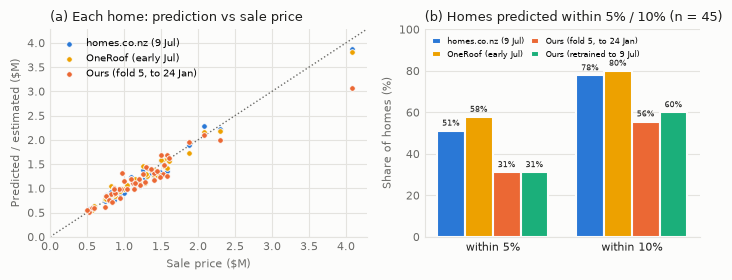

In [8]:
import matplotlib.pyplot as plt

SURFACE, INK, INK_MUTED, GRID = "#fcfcfb", "#1f1f1e", "#6b6b68", "#e4e3df"
# Our model keeps the colour it has in the report's other charts (orange).
COLORS = {"homes.co.nz (9 Jul)": "#2a78d6", "Ours (fold 5, to 24 Jan)": "#eb6834",
          "Ours (retrained to 9 Jul)": "#1baf7a", "OneRoof (early Jul)": "#eda100"}


def style(ax):
    ax.set_facecolor(SURFACE)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=INK_MUTED, labelsize=8, length=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)


fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.9), facecolor=SURFACE,
                         gridspec_kw={"width_ratios": [1.15, 1]})

# (a) Predicted vs actual, one dot per home; the diagonal is a perfect prediction.
ax = axes[0]
style(ax)
lim = [0, cmp[["sale_price"] + list(PREDICTORS.values())].max().max() / 1e6 * 1.05]
ax.plot(lim, lim, color=INK_MUTED, linewidth=1, linestyle=":")
# The retrained model is left out of the scatter to keep it readable (it is in panel b).
for name, col in [(n, c) for n, c in PREDICTORS.items() if n != "Ours (retrained to 9 Jul)"]:
    ax.scatter(cmp["sale_price"] / 1e6, cmp[col] / 1e6, s=16, color=COLORS[name],
               edgecolor=SURFACE, linewidth=0.6, label=name, zorder=3)
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel("Sale price (\\$M)", fontsize=8, color=INK_MUTED)
ax.set_ylabel("Predicted / estimated (\\$M)", fontsize=8, color=INK_MUTED)
ax.set_title("(a) Each home: prediction vs sale price", fontsize=9, color=INK, loc="left")
ax.legend(fontsize=7, frameon=False, loc="upper left")

# (b) Share of homes within 5% and 10% of the sale price.
ax = axes[1]
style(ax)
ax.grid(axis="x", visible=False)
bands = ["within 5% (share)", "within 10% (share)"]
width = 0.2
for i, name in enumerate(PREDICTORS):
    xs = np.arange(len(bands)) + (i - 1.5) * width
    vals = summary.loc[name, bands].values
    ax.bar(xs, vals, width=width, color=COLORS[name], edgecolor=SURFACE, linewidth=1.5, label=name)
    for x, v in zip(xs, vals):
        ax.text(x, v + 1.5, f"{v:.0f}%", ha="center", va="bottom", fontsize=6, color=INK)
ax.set_xticks(range(len(bands)))
ax.set_xticklabels(["within 5%", "within 10%"], fontsize=8, color=INK)
ax.set_ylim(0, 100)
ax.set_ylabel("Share of homes (%)", fontsize=8, color=INK_MUTED)
ax.set_title(f"(b) Homes predicted within 5% / 10% (n = {len(cmp)})", fontsize=9, color=INK, loc="left")
ax.legend(fontsize=6, frameon=False, loc="upper left", ncol=2, handlelength=1, columnspacing=0.8)

plt.tight_layout()
plt.savefig("figures/online_valuation_comparison.png", dpi=300, bbox_inches="tight", facecolor=SURFACE)
plt.show()

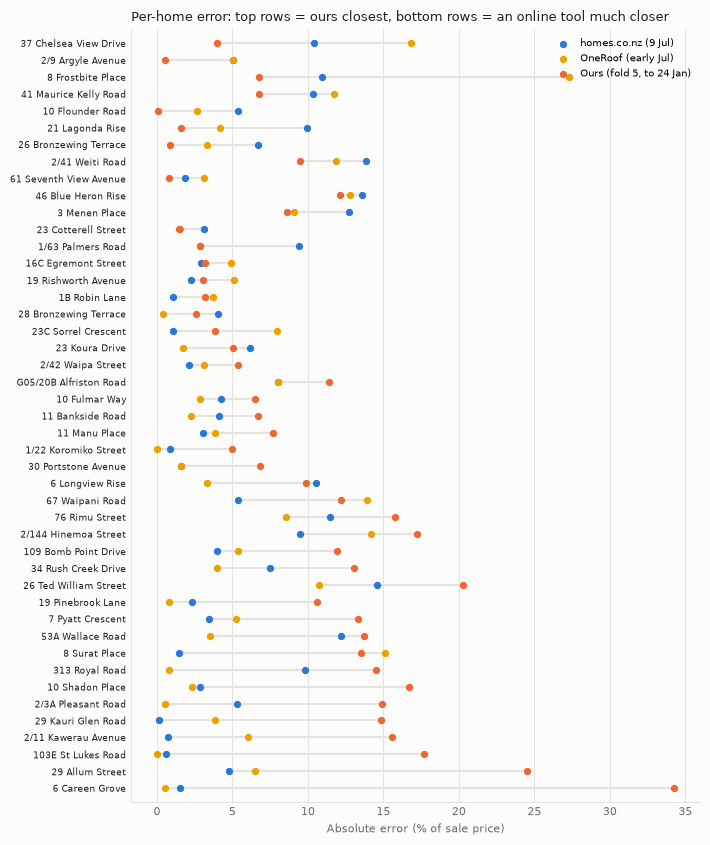

In [9]:
# Per-home absolute % error: ours (fold 5) vs the better of the two online tools.
# Sorted by our error minus the best online error, so the homes where ours is
# closest come first.
ours_abs = abs_err["Ours (fold 5, to 24 Jan)"]
best_online = np.minimum(abs_err["homes.co.nz (9 Jul)"], abs_err["OneRoof (early Jul)"])
gap = ours_abs - best_online
order = np.argsort(gap)
labels = cmp["address"].str.split(",").str[0].values
SHOWN = ["homes.co.nz (9 Jul)", "OneRoof (early Jul)", "Ours (fold 5, to 24 Jan)"]

fig, ax = plt.subplots(figsize=(7.2, 0.17 * len(cmp) + 0.9), facecolor=SURFACE)
style(ax)
ax.grid(axis="y", visible=False)
for row, i in enumerate(order):
    vals = [abs_err[n][i] for n in SHOWN]
    ax.plot([min(vals), max(vals)], [row, row], color=GRID, linewidth=1.5, zorder=1)
for n in SHOWN:
    ax.scatter(abs_err[n][order], range(len(cmp)), s=18, color=COLORS[n], label=n, zorder=3)
ax.set_yticks(range(len(cmp)))
ax.set_yticklabels(labels[order], fontsize=6.5, color=INK)
ax.set_xlabel("Absolute error (% of sale price)", fontsize=8, color=INK_MUTED)
ax.set_title("Per-home error: top rows = ours closest, bottom rows = an online tool much closer",
             fontsize=9, color=INK, loc="left")
ax.legend(fontsize=7, frameon=False, loc="upper right")
ax.set_ylim(-0.8, len(cmp) - 0.2)
ax.invert_yaxis()  # row 0 (ours closest relative to homes.co.nz) at the top
plt.tight_layout()
plt.savefig("figures/online_valuation_per_home.png", dpi=300, bbox_inches="tight", facecolor=SURFACE)
plt.show()

### 4.1 Same per-home chart, compact layout for the report

One column wide (3.5 in) so it prints at full size in the two-column
paper. Homes run left to right in the same order as above (ours closest
relative to the better online tool on the left).

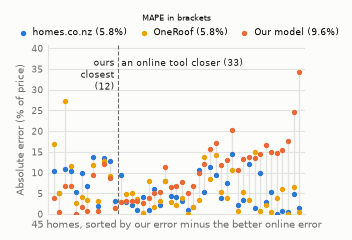

In [10]:
n_ours_closest = int((gap < 0).sum())
x = np.arange(len(cmp))
SHORT = {"homes.co.nz (9 Jul)": "homes.co.nz", "OneRoof (early Jul)": "OneRoof",
         "Ours (fold 5, to 24 Jan)": "Our model"}

fig, ax = plt.subplots(figsize=(3.5, 2.5), facecolor=SURFACE)
style(ax)
ax.grid(axis="x", visible=False)
lo = np.min([abs_err[n] for n in SHOWN], axis=0)[order]
hi = np.max([abs_err[n] for n in SHOWN], axis=0)[order]
ax.vlines(x, lo, hi, color=GRID, linewidth=1, zorder=1)
for n in SHOWN:
    ax.scatter(x, abs_err[n][order], s=8, color=COLORS[n],
               label=f"{SHORT[n]} ({abs_err[n].mean():.1f}%)", zorder=3)

# Divider: left = ours closer than both online tools; right = at least one tool closer.
split = n_ours_closest - 0.5
ax.axvline(split, color=INK_MUTED, linestyle="--", linewidth=0.8)
top = hi.max() * 1.1
ax.text(split - 0.6, top, f"ours\nclosest\n({n_ours_closest})", ha="right", va="top", fontsize=6.5, color=INK)
ax.text(split + 0.6, top, f"an online tool closer ({len(cmp) - n_ours_closest})",
        ha="left", va="top", fontsize=6.5, color=INK)

ax.set_xticks([])
ax.set_xlim(-1, len(cmp))
ax.set_ylim(0, top * 1.08)
ax.tick_params(labelsize=6.5)
ax.set_xlabel(f"{len(cmp)} homes, sorted by our error minus the better online error",
              fontsize=7, color=INK_MUTED)
ax.set_ylabel("Absolute error (% of price)", fontsize=7, color=INK_MUTED)
ax.legend(title="MAPE in brackets", title_fontsize=6, fontsize=6.5, frameon=False,
          loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, handletextpad=0.1, columnspacing=0.8)
plt.tight_layout()
plt.savefig("figures/online_valuation_per_home_report.png", dpi=300, bbox_inches="tight", facecolor=SURFACE)
plt.show()

## 5. Reading the result

- **Both online tools are clearly more accurate on these 45 homes.**
  homes.co.nz and OneRoof both reach a MAPE of 5.8%, against 9.6% for our
  model. OneRoof has the lowest typical error (median 3.8%) and puts 58% of
  homes within 5% of the sale price; homes.co.nz puts 51% there; ours 31%.
- **The gap is not luck.** The paired bootstrap interval for the MAPE gap
  is about 1.6--6.3 points against homes.co.nz and 1.3--6.5 points against
  OneRoof; both exclude zero, and the Wilcoxon tests agree (p < 0.01).
- **Ours is closest on 12 of the 45 homes (27%)**: closer than homes.co.nz
  on 36% of homes and closer than OneRoof on 40%.
- **It is not a timing problem.** Retraining our model on sales up to
  9 July (the capture date) does not close the gap (MAPE 9.9%).
- **Where ours misses most** (right end of the per-home chart: e.g. 6 Careen
  Grove +34%, 29 Allum Street -25%) are homes whose value depends on
  things our 27 features cannot see, or homes near the top of the price
  range where we have few sales.
- **Data checks.** One OneRoof value was a typo in the hand-collected
  table (home 7, 3 Menen Place, entered as $120,000 instead of $1,200,000)
  and has been corrected in `online_valuation.csv`. The OneRoof recording
  date was early July (exact day not noted); either way it is before
  every sale (`ONEROOF_DATE` is set to the latest possible day, 9 July).
- **Small sample.** 45 homes from three weeks of sales, mostly in the
  middle of the market, so the exact size of the gap is uncertain.